# 4. whylogs: perfis, drift, regras e monitoramento diário

O **whylogs** funciona de um jeito diferente do Evidently e do Deepchecks. Em vez de guardar e comparar os dados brutos, ele transforma cada lote de dados num **perfil**: um resumo estatístico compacto (contagens, nulos, média, quantis, histogramas aproximados, valores mais frequentes). Todo o resto é feito a partir dos perfis: drift, regras de qualidade e métricas de desempenho.

Três propriedades dos perfis importam para um sistema de monitoramento:
- **crescem muito devagar**: dez vezes mais linhas geram um perfil só um pouco maior, então guardar um perfil por dia durante anos é barato;
- **combináveis** (*mergeable*): perfis diários podem ser somados num perfil mensal sem reprocessar os dados;
- **sem dados brutos**: o perfil guarda estatísticas, não linhas, o que facilita guardar histórico e compartilhar.

Objetivos do notebook:
- criar os perfis da **referência** (holdout de 2011) e da **produção** (2012) e explorar o que eles contêm;
- medir o **drift** com os dois tipos de teste do whylogs (p-valor e distância de Hellinger) e entender por que eles discordam;
- medir o **desempenho** do modelo a partir de perfis de regressão;
- montar um **gate PASS/FAIL** com as *constraints* do whylogs;
- fazer o **monitoramento diário**, como o whylogs foi pensado para ser usado, e consolidar em **perfis mensais**.

### Evidently × Deepchecks × whylogs (mapa rápido)

| Tarefa | Evidently | Deepchecks | whylogs |
|---|---|---|---|
| Unidade de trabalho | tabelas de referência e atual | `Dataset` + modelo | **perfil** de cada lote |
| Drift das features | `DataDriftPreset` | `FeatureDrift` | `summary_drift_report` / `calculate_drift_scores` |
| Drift do target / previsões | `TargetDriftPreset` | `LabelDrift` / `PredictionDrift` | o mesmo relatório, colunas `cnt` e `prediction` |
| Desempenho | `RegressionPreset` | `model_evaluation()` | `log_regression_metrics` (RMSE, MAE) |
| Regras PASS/FAIL | `TestSuite` | `Suite` + conditions | `ConstraintsBuilder` + constraints |
| Precisa do modelo? | não (colunas de previsão) | **sim** | não (colunas de previsão) |
| Histórico ao longo do tempo | relatórios separados | relatórios separados | perfis com data, **somáveis** |

In [1]:
# Imports
import sys
from pathlib import Path
import json
import warnings
import datetime as dt
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
import logging
logging.getLogger("whylogs").setLevel(logging.ERROR)  # o whylogs avisa sobre histogramas de colunas quase constantes

sys.path.append("..")
from src.bike import FEATURES, NUM_FEATURES, CAT_FEATURES, LABEL, CountModel, rmse

try:
    import whylogs as why
    from whylogs.viz import NotebookProfileVisualizer
    from whylogs.viz.drift.column_drift_algorithms import calculate_drift_scores, Hellinger
    from whylogs.core.constraints import ConstraintsBuilder, MetricConstraint, MetricsSelector
    from whylogs.core.constraints.factories import (
        is_in_range, no_missing_values, frequent_strings_in_reference_set, mean_between_range,
    )
    WHYLOGS_AVAILABLE = True
    print("whylogs versão:", why.__version__)
except Exception as e:
    WHYLOGS_AVAILABLE = False
    print("Erro ao carregar whylogs:", e)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
print("whylogs disponível:", WHYLOGS_AVAILABLE)

whylogs versão: 1.6.4
whylogs disponível: True


## 1 — Carregar dados e modelo, e gerar as previsões

Diferente do Deepchecks, o whylogs **não chama o modelo**: ele só resume tabelas. Por isso, como no projeto do Evidently, a previsão entra como uma coluna da tabela (`prediction`), ao lado do valor real (`cnt`).

In [2]:
DATA_PATH = Path("..") / "data" / "processed" / "bike_clean.parquet"
MODEL_PATH = Path("..") / "models" / "pipeline_2011.joblib"
METRICS_PATH = Path("..") / "models" / "metrics.json"
RUNS_DIR = Path("..") / "runs"
PROFILES_DIR = RUNS_DIR / "profiles"
PROFILES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
metrics = json.loads(METRICS_PATH.read_text())
model = CountModel(joblib.load(MODEL_PATH), metrics["sigma_used"])

df["prediction"] = model.predict(df)
COLS = FEATURES + [LABEL, "prediction"]           # o que entra nos perfis
NUM_COLS = NUM_FEATURES + [LABEL, "prediction"]  # colunas numéricas (drift por Hellinger)
print("Dados:", df.shape, "| colunas perfiladas:", len(COLS))

Dados: (17379, 18) | colunas perfiladas: 13


## 2 — Janelas

| Janela | Período | Uso |
|---|---|---|
| Referência | 2011, dias 24+ de cada mês (holdout que o modelo não viu) | comparação anual e desempenho de referência |
| Produção | 2012 inteiro | lote a monitorar |
| Mesmo mês de 2011 | cada mês de 2011 inteiro | referência do monitoramento mensal (evita alarmes de sazonalidade) |

In [3]:
is_2011, is_2012 = df["year"] == 2011, df["year"] == 2012
ref_data = df[is_2011 & (df["date"].dt.day >= 24)]
cur_data = df[is_2012]
print(f"Referência: {len(ref_data)} horas | Produção: {len(cur_data)} horas")

Referência: 2083 horas | Produção: 8734 horas


## 3 — Perfis: o que o whylogs guarda

`why.log(tabela)` lê a tabela uma vez e devolve o perfil. `.view()` é a versão "congelada" do perfil, usada para comparar, salvar e gerar relatórios.

In [4]:
if WHYLOGS_AVAILABLE:
    ref_view = why.log(ref_data[COLS]).profile().view()
    cur_view = why.log(cur_data[COLS]).profile().view()

    resumo_cols = ["counts/n", "counts/null", "distribution/mean", "distribution/stddev", "distribution/min",
                   "distribution/q_25", "distribution/median", "distribution/q_75", "distribution/max",
                   "cardinality/est"]
    perfil_2012 = cur_view.to_pandas()
    display(perfil_2012.loc[["cnt", "prediction", "temp", "humidity"], resumo_cols].T.round(1))

    freq = perfil_2012.loc["weather", "frequent_items/frequent_strings"]
    print("valores mais frequentes de weather (estimados):", [(f.value, int(f.est)) for f in freq])

column,cnt,prediction,temp,humidity
counts/n,8734.0,8734.0,8734.0,8734.0
counts/null,0.0,0.0,0.0,0.0
distribution/mean,234.7,145.8,20.7,61.1
distribution/stddev,208.9,130.6,7.7,18.8
distribution/min,1.0,0.9,0.8,16.0
distribution/q_25,54.0,34.7,13.9,46.0
distribution/median,191.0,116.6,21.3,61.0
distribution/q_75,348.0,214.1,27.1,77.0
distribution/max,977.0,647.5,41.0,100.0
cardinality/est,859.1,8689.1,50.0,81.0


valores mais frequentes de weather (estimados): [('clear', 5768), ('mist', 2326), ('light_rain_snow', 638), ('heavy_rain_snow', 2)]


Cada linha acima é uma **métrica** guardada no perfil; cada coluna, uma coluna da tabela original. Os quantis e a cardinalidade são **aproximados** (o whylogs usa *sketches*, estruturas que estimam esses valores com memória fixa), e é isso que mantém o perfil pequeno. Para colunas de texto, como `weather`, ele guarda os valores mais frequentes com suas contagens estimadas.

### Tamanho e persistência

Um perfil é salvo em um arquivo binário (`.bin`) e pode ser lido de volta depois, sem os dados originais. Comparamos o tamanho do perfil com o tamanho dos mesmos dados em CSV, para lotes de tamanhos bem diferentes. O último lote é o dataset inteiro replicado 10 vezes, só para testar o comportamento com 170 mil linhas.

In [5]:
def tamanho_kb(path):
    return Path(path).stat().st_size / 1024

if WHYLOGS_AVAILABLE:
    lotes = {
        "1 dia (01/07/2012)": cur_data[cur_data["date"] == "2012-07-01"],
        "1 mês (jul/2012)": cur_data[cur_data["month"] == 7],
        "Referência (holdout 2011)": ref_data,
        "Produção (2012)": cur_data,
        "Dataset inteiro": df,
        "Dataset inteiro × 10": pd.concat([df] * 10, ignore_index=True),
    }
    rows = []
    for nome, lote in lotes.items():
        csv_path = PROFILES_DIR / "_tmp.csv"
        lote[COLS].to_csv(csv_path, index=False)
        view = why.log(lote[COLS]).profile().view()
        bin_path = PROFILES_DIR / "_tmp.bin"
        view.write(str(bin_path))
        rows.append({"lote": nome, "linhas": len(lote), "CSV (KB)": tamanho_kb(csv_path), "perfil (KB)": tamanho_kb(bin_path)})
    (PROFILES_DIR / "_tmp.csv").unlink(); (PROFILES_DIR / "_tmp.bin").unlink()
    tamanhos = pd.DataFrame(rows).set_index("lote")
    tamanhos["perfil / CSV"] = tamanhos["perfil (KB)"] / tamanhos["CSV (KB)"]
    display(tamanhos.style.format({"CSV (KB)": "{:,.0f}", "perfil (KB)": "{:,.0f}", "perfil / CSV": "{:.1%}"}))

    # salva os perfis principais e confirma que eles podem ser lidos de volta
    ref_view.write(str(PROFILES_DIR / "referencia_2011.bin"))
    cur_view.write(str(PROFILES_DIR / "producao_2012.bin"))
    relido = why.read(str(PROFILES_DIR / "producao_2012.bin")).view()
    print("média de cnt no perfil relido:", round(relido.get_column("cnt").get_metric("distribution").mean.value, 1),
          "| nos dados:", round(cur_data["cnt"].mean(), 1))

,linhas,CSV (KB),perfil (KB),perfil / CSV
lote,,,,
1 dia (01/07/2012),24,2,7,391.9%
1 mês (jul/2012),744,50,73,145.3%
Referência (holdout 2011),2083,140,139,99.2%
Produção (2012),8734,588,202,34.4%
Dataset inteiro,17379,"1,169",222,18.9%
Dataset inteiro × 10,173790,"11,691",243,2.1%


média de cnt no perfil relido: 234.7 | nos dados: 234.7


**Leitura:** o perfil **não** tem tamanho fixo, mas cresce muito devagar.

- **Lotes pequenos:** o perfil é **maior** que os dados. Um dia (24 linhas) vira 7 KB de perfil contra 2 KB de CSV, porque as estruturas de resumo têm um tamanho mínimo.
- **Empate:** acontece por volta de 2 mil linhas (a referência).
- **Lotes grandes:** a vantagem aparece. 2012 inteiro ocupa 34% do CSV, e o dataset replicado 10 vezes (174 mil linhas) ocupa só 2,1%: 10 vezes mais linhas deixaram o perfil apenas 10% maior.

Para guardar histórico, a conta é outra: um perfil por dia custa o mesmo quer o dia tenha mil ou um milhão de linhas, e dispensa guardar os dados brutos.

### Relatório do perfil (HTML)

O `NotebookProfileVisualizer` transforma perfis em relatórios. O primeiro descreve só o perfil de produção.

In [6]:
def salvar_html(html, nome):
    path = RUNS_DIR / f"{nome}.html"
    path.unlink(missing_ok=True)
    NotebookProfileVisualizer.write(rendered_html=html, html_file_name=str(RUNS_DIR / nome))
    print("Relatório salvo em:", path)

if WHYLOGS_AVAILABLE:
    viz = NotebookProfileVisualizer()
    viz.set_profiles(target_profile_view=cur_view)
    salvar_html(viz.profile_summary(cell_height="2300px"), "whylogs_profile_summary")

Relatório salvo em: ../runs/whylogs_profile_summary.html


## 4 — Drift: dois testes, duas respostas

O whylogs calcula drift comparando dois perfis. Por padrão ele usa **testes de hipótese**: Kolmogorov-Smirnov (KS) para números e qui-quadrado para categorias. A decisão sai do **p-valor**: abaixo de 0,05 é `DRIFT`, entre 0,05 e 0,15 é `POSSIBLE_DRIFT`.

A alternativa é a **distância de Hellinger**, que mede o **tamanho** da diferença entre as distribuições (0 = iguais, 1 = totalmente diferentes). Os limites padrão são: abaixo de 0,15 não há drift, de 0,15 a 0,4 é possível, acima de 0,4 é drift. Ela só se aplica a colunas numéricas.

In [7]:
def drift_df(target, reference, hellinger=False, cols=COLS):
    dm = {c: Hellinger() for c in NUM_COLS} if hellinger else None
    scores = calculate_drift_scores(target_view=target, reference_view=reference, drift_map=dm, with_thresholds=True)
    rows = []
    for c in cols:
        s = scores.get(c)
        if s:
            rows.append({"coluna": c, "algoritmo": s["algorithm"], "estatística": s["statistic"],
                         "p-valor": s["pvalue"], "veredito": s["drift_category"]})
    return pd.DataFrame(rows).set_index("coluna")

if WHYLOGS_AVAILABLE:
    d_pvalor = drift_df(cur_view, ref_view)
    d_hell = drift_df(cur_view, ref_view, hellinger=True)
    comparacao = pd.DataFrame({
        "teste padrão": d_pvalor["algoritmo"],
        "estatística": d_pvalor["estatística"].round(3),
        "p-valor": d_pvalor["p-valor"].apply(lambda p: f"{p:.1e}"),
        "veredito (p-valor)": d_pvalor["veredito"],
        "Hellinger": d_hell["estatística"].where(d_hell["algoritmo"] == "hellinger").round(3),
        "veredito (Hellinger)": d_hell["veredito"].where(d_hell["algoritmo"] == "hellinger"),
    })
    display(comparacao)
    print("colunas com DRIFT pelo p-valor:", int((comparacao["veredito (p-valor)"] == "DRIFT").sum()), "de", len(comparacao))

,teste padrão,estatística,p-valor,veredito (p-valor),Hellinger,veredito (Hellinger)
coluna,,,,,,
hour,ks,0.006,1.0e+00,NO_DRIFT,0.010,NO_DRIFT
month,ks,0.030,9.4e-02,POSSIBLE_DRIFT,0.040,NO_DRIFT
holiday,ks,0.004,1.0e+00,NO_DRIFT,0.008,NO_DRIFT
workingday,ks,0.007,1.0e+00,NO_DRIFT,0.005,NO_DRIFT
temp,ks,0.071,9.7e-08,DRIFT,0.116,NO_DRIFT
atemp,ks,0.072,3.9e-08,DRIFT,0.128,NO_DRIFT
humidity,ks,0.087,1.4e-11,DRIFT,0.110,NO_DRIFT
windspeed,ks,0.018,6.3e-01,NO_DRIFT,0.066,NO_DRIFT
season,chi-square,33.750,2.2e-07,DRIFT,NaN,NaN


colunas com DRIFT pelo p-valor: 7 de 13


**Leitura:** os dois testes contam histórias diferentes.

- **Pelo p-valor** (padrão do whylogs), **7 de 13 colunas têm drift**: temperatura, sensação térmica, umidade, estação, dia da semana, tempo e `cnt`. Um gestor que lesse só o veredito acharia que o clima mudou drasticamente.
- **Pela distância de Hellinger**, só `cnt` passa do limite (0,23, "possível drift"). Temperatura, sensação térmica e umidade ficam entre 0,11 e 0,13, abaixo de 0,15.
- **`prediction` não tem drift em nenhum dos dois** (KS 0,025; Hellinger 0,045). É a mesma lição do Deepchecks: as previsões não mudaram, e só o valor real mostra o problema.

A estatística KS da temperatura é só 0,07, uma diferença pequena. O que a transforma em "DRIFT" é o tamanho das amostras (2.083 × 8.734 linhas), como mostra o teste a seguir. As colunas categóricas não têm versão Hellinger no whylogs 1.6 e continuam no qui-quadrado, que tem o mesmo problema.

### Por que o p-valor acusa tanto: o tamanho da amostra

O teste de hipótese pergunta se a diferença **existe**, não se ela **importa**. Com amostras grandes, qualquer diferença, por menor que seja, vira significativa. Para mostrar isso, repetimos o teste para a temperatura usando amostras aleatórias de tamanhos diferentes das mesmas duas janelas: a diferença real (a estatística KS) fica parecida, mas o veredito muda.

In [8]:
if WHYLOGS_AVAILABLE:
    rng = np.random.default_rng(42)
    rows = []
    for n in [100, 300, 1000, len(ref_data)]:
        a = ref_data.sample(n=n, random_state=42)[["temp"]]
        b = cur_data.sample(n=n, random_state=42)[["temp"]]
        s = calculate_drift_scores(target_view=why.log(b).profile().view(),
                                   reference_view=why.log(a).profile().view(), with_thresholds=True)["temp"]
        rows.append({"linhas por janela": n, "estatística KS": round(s["statistic"], 3),
                     "p-valor": f"{s['pvalue']:.3f}", "veredito": s["drift_category"]})
    display(pd.DataFrame(rows).set_index("linhas por janela"))

,estatística KS,p-valor,veredito
linhas por janela,,,
100,0.110,0.544,NO_DRIFT
300,0.070,0.435,NO_DRIFT
1000,0.073,0.009,DRIFT
2083,0.067,0.000,DRIFT


**Leitura:** a diferença de temperatura entre as duas janelas é sempre parecida (KS entre 0,07 e 0,11), mas o veredito muda com o número de linhas:

- **100 ou 300 linhas por janela:** sem drift;
- **1.000 linhas ou mais:** drift.

Em produção, os lotes costumam ser grandes, então o teste padrão do whylogs tende a gerar **alarmes demais**. A recomendação é usar Hellinger nas colunas numéricas, ou olhar a estatística em vez do veredito.

### Relatórios de drift (HTML)

Geramos dois relatórios com os mesmos perfis: um com o teste padrão (p-valor) e outro com Hellinger nas colunas numéricas.

In [9]:
if WHYLOGS_AVAILABLE:
    viz = NotebookProfileVisualizer()
    viz.set_profiles(target_profile_view=cur_view, reference_profile_view=ref_view)
    salvar_html(viz.summary_drift_report(height="2400px"), "whylogs_drift_report_pvalue")

    viz = NotebookProfileVisualizer()
    viz.set_profiles(target_profile_view=cur_view, reference_profile_view=ref_view)
    viz.add_drift_config(column_names=NUM_COLS, algorithm=Hellinger())
    salvar_html(viz.summary_drift_report(height="2400px"), "whylogs_drift_report_hellinger")

Relatório salvo em: ../runs/whylogs_drift_report_pvalue.html


Relatório salvo em: ../runs/whylogs_drift_report_hellinger.html


## 5 — Desempenho do modelo a partir de perfis

`why.log_regression_metrics` cria um perfil especial com as somas necessárias para calcular RMSE e MAE (soma dos erros, dos erros absolutos e dos erros ao quadrado). Por isso esses perfis também podem ser **somados**: perfis diários viram mensais sem perder precisão.

In [10]:
def perf(data):
    rm = why.log_regression_metrics(data, target_column=LABEL, prediction_column="prediction").view() \
            .model_performance_metrics.regression_metrics
    return rm

def perf_dict(rm, soma_real):
    return {"horas": rm.count, "RMSE": rm.root_mean_squared_error(), "MAE": rm.mean_absolute_error(),
            "viés da soma": rm.sum_diff / soma_real}  # sum_diff = soma de (previsto - real)

if WHYLOGS_AVAILABLE:
    perf_ref, perf_cur = perf(ref_data), perf(cur_data)
    desempenho = pd.DataFrame({
        "Referência 2011": perf_dict(perf_ref, ref_data[LABEL].sum()),
        "Produção 2012": perf_dict(perf_cur, cur_data[LABEL].sum()),
    }).T
    display(desempenho.style.format({"horas": "{:,.0f}", "RMSE": "{:.1f}", "MAE": "{:.1f}", "viés da soma": "{:+.1%}"}))
    print("conferência: RMSE calculado direto nos dados =", round(rmse(cur_data[LABEL], cur_data["prediction"]), 1))

,horas,RMSE,MAE,viés da soma
Referência 2011,"2,083",41.1,26.2,-0.9%
Produção 2012,"8,734",130.2,93.0,-37.9%


conferência: RMSE calculado direto nos dados = 130.2


**Leitura:** os perfis de regressão reproduzem exatamente o RMSE calculado nos dados (130,2) e o do projeto do Deepchecks.

- **Erro:** passa de 41 para 130 aluguéis por hora.
- **Viés:** a soma prevista cai de −0,9% para −37,9%.

O whylogs entrega as métricas, mas **não traz um relatório de desempenho pronto** como o `RegressionPreset` do Evidently ou o `model_evaluation()` do Deepchecks: não há gráfico de resíduos nem busca automática dos piores segmentos.

## 6 — Gate de produção (PASS / FAIL) com constraints

As **constraints** do whylogs são regras avaliadas **sobre o perfil**, sem tocar nos dados brutos. A biblioteca traz regras prontas (faixa de valores, ausência de nulos, valores dentro de um conjunto, média dentro de um intervalo), e é possível escrever regras próprias sobre qualquer métrica do perfil.

Para que o gate também cubra o **desempenho**, o perfil do gate inclui duas colunas extras: `erro` (previsto − real) e `erro_abs`. Assim, viés e erro médio viram regras comuns sobre a média dessas colunas.

| Grupo | Regra |
|---|---|
| Integridade | `hour` entre 0 e 23; `temp` entre −10 e 45 °C; `humidity` entre 0 e 100; sem nulos em `temp` e `cnt` |
| Categorias | `weather`, `season`, `weekday` só com valores vistos na referência |
| Volume | pelo menos 99% das horas esperadas no período |
| Previsões | média de `prediction` a até ±20% da referência |
| Target | média de `cnt` a até ±20% da referência |
| Viés | média de `erro` a até ±10% da média de `cnt` da referência |
| Erro | média de `erro_abs` (MAE) até 1,3× a da referência |

In [11]:
def media(view, col):
    return view.get_column(col).get_metric("distribution").mean.value

def com_erro(data):
    out = data[COLS].copy()
    out["erro"] = out["prediction"] - out[LABEL]
    out["erro_abs"] = out["erro"].abs()
    return out

def horas_esperadas(data):
    return int((data["date"].max() - data["date"].min()).days + 1) * 24

def regra(nome, metrica, coluna, condicao):
    return MetricConstraint(name=nome, condition=condicao, metric_selector=MetricsSelector(metric_name=metrica, column_name=coluna))

def gate(target_data, ref_view_erro):
    view = why.log(com_erro(target_data)).profile().view()
    ref_cnt, ref_pred, ref_mae = (round(media(ref_view_erro, c), 1) for c in [LABEL, "prediction", "erro_abs"])
    minimo = int(0.99 * horas_esperadas(target_data))
    cb = ConstraintsBuilder(dataset_profile_view=view)
    cb.add_constraint(is_in_range(column_name="hour", lower=0, upper=23))
    cb.add_constraint(is_in_range(column_name="temp", lower=-10, upper=45))
    cb.add_constraint(is_in_range(column_name="humidity", lower=0, upper=100))
    cb.add_constraint(no_missing_values(column_name="temp"))
    cb.add_constraint(no_missing_values(column_name=LABEL))
    for c in CAT_FEATURES:
        cb.add_constraint(frequent_strings_in_reference_set(column_name=c, reference_set=set(df[is_2011][c].unique())))
    cb.add_constraint(regra(f"volume: pelo menos {minimo} horas (99% das esperadas)", "counts", LABEL, lambda m: m.n.value >= minimo))
    r1 = lambda x: round(x, 1)
    cb.add_constraint(mean_between_range(column_name="prediction", lower=r1(0.8 * ref_pred), upper=r1(1.2 * ref_pred)))
    cb.add_constraint(mean_between_range(column_name=LABEL, lower=r1(0.8 * ref_cnt), upper=r1(1.2 * ref_cnt)))
    cb.add_constraint(mean_between_range(column_name="erro", lower=r1(-0.1 * ref_cnt), upper=r1(0.1 * ref_cnt)))
    cb.add_constraint(mean_between_range(column_name="erro_abs", lower=0, upper=r1(1.3 * ref_mae)))
    return cb.build()

if WHYLOGS_AVAILABLE:
    ref_view_erro = why.log(com_erro(ref_data)).profile().view()
    constraints_2012 = gate(cur_data, ref_view_erro)

    def grupo(nome):
        for prefixo, g in [("volume", "Volume"), ("cnt mean", "Target"), ("prediction mean", "Previsões"),
                           ("erro mean", "Viés"), ("erro_abs mean", "Erro (MAE)"), ("season", "Categorias"),
                           ("weekday", "Categorias"), ("weather", "Categorias")]:
            if nome.startswith(prefixo):
                return g
        return "Integridade"

    rows = [{"grupo": grupo(r.name), "regra": r.name, "status": "PASS" if r.passed else "FAIL"}
            for r in constraints_2012.generate_constraints_report()]
    ordem = ["Integridade", "Categorias", "Volume", "Previsões", "Target", "Viés", "Erro (MAE)"]
    gate_table = pd.DataFrame(rows).sort_values("grupo", key=lambda c: c.map(ordem.index), kind="stable").reset_index(drop=True)
    gate_table.to_csv(RUNS_DIR / "whylogs_gate_summary.csv", index=False)

    viz = NotebookProfileVisualizer()
    viz.set_profiles(target_profile_view=cur_view)
    salvar_html(viz.constraints_report(constraints_2012), "whylogs_constraints_report")

    print("\n>>> LOTE 2012", "APROVADO" if constraints_2012.validate() else "REPROVADO", "<<<")
    display(gate_table)

Relatório salvo em: ../runs/whylogs_constraints_report.html

>>> LOTE 2012 REPROVADO <<<


,grupo,regra,status
0,Integridade,"hour is in range [0,23]",PASS
1,Integridade,"temp is in range [-10,45]",PASS
2,Integridade,temp has no missing values,PASS
3,Integridade,"humidity is in range [0,100]",PASS
4,Integridade,cnt has no missing values,PASS
5,Categorias,"season values in set {'spring', 'fall', 'summe...",PASS
6,Categorias,"weekday values in set {'fri', 'sun', 'sat', 'm...",PASS
7,Categorias,"weather values in set {'clear', 'mist', 'heavy...",PASS
8,Volume,volume: pelo menos 8696 horas (99% das esperadas),PASS
9,Previsões,prediction mean between 113.9 and 170.9 (inclu...,PASS


**Leitura:** o lote de 2012 é **reprovado** em 3 das 13 regras.

**Reprovou:**
- **Target:** a média de `cnt` é 234,7, fora da faixa 115,0–172,4.
- **Viés:** o erro médio está fora de ±14,4.
- **Erro (MAE):** o erro absoluto médio está acima de 34,1.

**Passou:**
- **Integridade e categorias:** faixas de valores, ausência de nulos e só categorias já vistas na referência.
- **Volume:** 8.734 horas, contra o mínimo de 8.696.
- **Previsões:** a média de `prediction` (145,8) está dentro de 113,9–170,9.

É de novo a lição central: tudo o que olha só entradas e previsões passa; o que compara com o valor real reprova. Um detalhe prático: os nomes das regras saem em inglês e com os limites calculados, o que é bom para auditoria, mas ruim para leitura por leigos. A coluna `grupo` foi criada para traduzir isso.

## 7 — Monitoramento diário (o uso natural do whylogs)

Em produção, o whylogs costuma rodar **dentro do pipeline de dados**: cada lote que chega gera um perfil com a sua data (`dataset_timestamp`), e só o perfil é guardado. Simulamos isso com um perfil por **dia** de 2012, para as features e para o desempenho.

In [12]:
def ts(day):
    return dt.datetime.combine(pd.Timestamp(day).date(), dt.time()).replace(tzinfo=dt.timezone.utc)

if WHYLOGS_AVAILABLE:
    dias_2012 = pd.date_range("2012-01-01", "2012-12-31", freq="D")
    perfis_dia, perf_dia = {}, {}
    for day, g in cur_data.groupby("date"):
        perfis_dia[day] = why.log(g[COLS], dataset_timestamp=ts(day)).profile().view()
        perf_dia[day] = why.log_regression_metrics(g, target_column=LABEL, prediction_column="prediction",
                                                   dataset_timestamp=ts(day)).view()
    print("perfis diários criados:", len(perfis_dia), "| dias no calendário de 2012:", len(dias_2012))

perfis diários criados: 366 | dias no calendário de 2012: 366


### Volume: quantas horas chegaram em cada dia

A métrica `counts/n` de cada perfil diário diz quantas linhas aquele dia teve. Uma regra simples, "pelo menos 20 das 24 horas", vira um monitor de volume.

dias reprovados na regra de volume: ['29/10', '30/10']
dias sem nenhum dado (sem perfil): []


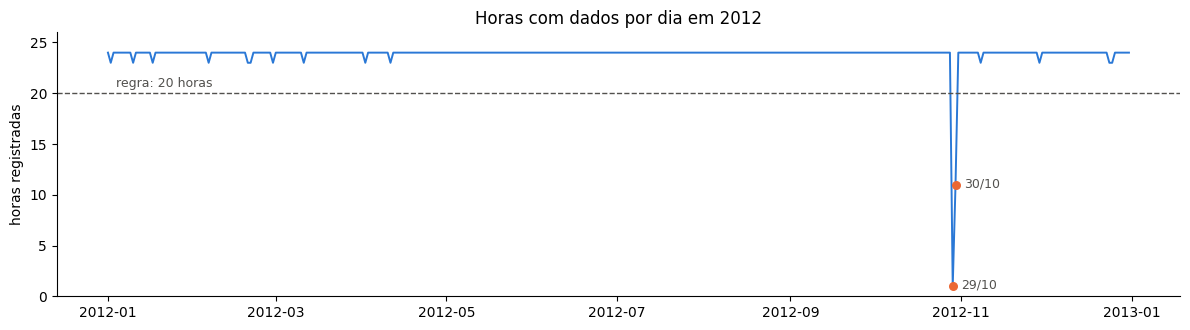

In [13]:
if WHYLOGS_AVAILABLE:
    horas_dia = pd.Series({d: perfis_dia[d].get_column(LABEL).get_metric("counts").n.value if d in perfis_dia else 0
                           for d in dias_2012}, name="horas")

    falhas = []
    for d, view in perfis_dia.items():
        cb = ConstraintsBuilder(dataset_profile_view=view)
        cb.add_constraint(regra("pelo menos 20 horas no dia", "counts", LABEL, lambda m: m.n.value >= 20))
        if not cb.build().validate():
            falhas.append(d)
    faltando = [d for d in dias_2012 if d not in perfis_dia]
    print("dias reprovados na regra de volume:", [d.strftime("%d/%m") for d in falhas])
    print("dias sem nenhum dado (sem perfil):", [d.strftime("%d/%m") for d in faltando])

    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.plot(horas_dia.index, horas_dia.values, color=BLUE, lw=1.4)
    ax.axhline(20, color=GRAY, lw=1, ls="--"); ax.text(dias_2012[3], 20.6, "regra: 20 horas", color=GRAY, fontsize=9)
    for d in falhas:
        ax.annotate(d.strftime("%d/%m"), (d, horas_dia[d]), xytext=(6, -2), textcoords="offset points", fontsize=9, color=GRAY)
    ax.scatter(falhas, horas_dia[falhas], color=ORANGE, zorder=3, s=30)
    ax.set_ylim(0, 26); ax.set_ylabel("horas registradas"); ax.set_title("Horas com dados por dia em 2012")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); fig.savefig(RUNS_DIR / "whylogs_daily_volume_2012.png", dpi=130, bbox_inches="tight"); plt.show()

**Leitura:** a regra diária de volume pegou exatamente os dois dias do **furacão Sandy**: 29/10, com 1 hora registrada, e 30/10, com 11. Os pequenos vales para 23 horas ao longo do ano são horas que não aparecem no arquivo (sem aluguel ou com o sistema parado) e ficam acima do limite.

Essa é uma vantagem concreta sobre o Deepchecks, que não percebeu o Sandy, e vem do jeito do whylogs trabalhar: como cada lote vira um perfil com data, contar linhas por lote é natural. A regra anual de volume (seção 6) não pegou o problema, porque 36 horas somem num ano inteiro. **A granularidade do lote define o que o monitor consegue ver.**

Dias **sem nenhum dado** não geram perfil, e por isso não são reprovados por uma regra sobre o perfil. O notebook verifica isso à parte, comparando o calendário com os perfis existentes; em 2012 não houve nenhum.

### Somar perfis diários em perfis mensais

Os perfis diários de cada mês são somados (`merge`) em um perfil mensal, e conferimos se o resultado bate com o cálculo direto sobre os dados do mês. Os perfis mensais são salvos em `runs/profiles/`.

In [14]:
def somar(views):
    total = views[0]
    for v in views[1:]:
        total = total.merge(v)
    return total

if WHYLOGS_AVAILABLE:
    mensal_view, mensal_perf, checagem = {}, {}, []
    for m in range(1, 13):
        dias = [d for d in perfis_dia if d.month == m]
        mensal_view[m] = somar([perfis_dia[d] for d in dias])
        mensal_perf[m] = somar([perf_dia[d] for d in dias]).model_performance_metrics.regression_metrics
        mensal_view[m].write(str(PROFILES_DIR / f"producao_2012-{m:02d}.bin"))
        mes = cur_data[cur_data["month"] == m]
        checagem.append({"mês": m,
                         "horas (perfil somado)": mensal_view[m].get_column(LABEL).get_metric("counts").n.value,
                         "horas (dados)": len(mes),
                         "média cnt (perfil)": media(mensal_view[m], LABEL), "média cnt (dados)": mes[LABEL].mean(),
                         "RMSE (perfil)": mensal_perf[m].root_mean_squared_error(),
                         "RMSE (dados)": rmse(mes[LABEL], mes["prediction"])})
    checagem = pd.DataFrame(checagem).set_index("mês")
    iguais = np.allclose(checagem.iloc[:, 0::2].to_numpy(dtype=float), checagem.iloc[:, 1::2].to_numpy(dtype=float))
    print("perfis somados batem com o cálculo direto em todos os meses?", iguais)
    display(checagem.round(1).head(4))

perfis somados batem com o cálculo direto em todos os meses? True


,horas (perfil somado),horas (dados),média cnt (perfil),média cnt (dados),RMSE (perfil),RMSE (dados)
mês,,,,,,
1,741,741,130.6,130.6,107.1,107.1
2,692,692,149.0,149.0,110.2,110.2
3,743,743,221.9,221.9,166.0,166.0
4,718,718,242.7,242.7,150.8,150.8


## 8 — Monitoramento mês a mês

Cada mês de 2012 (perfil somado dos dias) é comparado com **o mesmo mês de 2011**:
- **drift** (Hellinger): mês de 2011 inteiro × mês de 2012, para `cnt`, `prediction` e a maior entre as features numéricas (sem `month`, que é constante dentro do mês);
- **desempenho**: RMSE e viés do perfil de regressão do mês, comparados com o holdout do mesmo mês de 2011 (dias 24+, que o modelo não viu).

Regras: Hellinger < 0,15 para `cnt` e `prediction`; RMSE até 1,3× a referência; viés da soma entre −10% e +10%.

In [15]:
if WHYLOGS_AVAILABLE:
    rows = []
    for m in range(1, 13):
        ref_mes = df[is_2011 & (df["month"] == m)]
        ref_mes_view = why.log(ref_mes[COLS]).profile().view()
        dh = drift_df(mensal_view[m], ref_mes_view, hellinger=True, cols=[c for c in NUM_COLS if c != "month"])
        feats = dh.drop(index=[LABEL, "prediction"])
        top = feats["estatística"].idxmax()
        rm_ref = perf(ref_mes[ref_mes["date"].dt.day >= 24])
        rm_cur = mensal_perf[m]
        vies = rm_cur.sum_diff / cur_data.loc[cur_data["month"] == m, LABEL].sum()
        rows.append({
            "mês": m, "horas 2012": rm_cur.count,
            "RMSE ref": rm_ref.root_mean_squared_error(), "RMSE 2012": rm_cur.root_mean_squared_error(), "viés 2012": vies,
            "Hellinger cnt": dh.loc[LABEL, "estatística"], "Hellinger prediction": dh.loc["prediction", "estatística"],
            "maior Hellinger feature": f"{top} ({feats.loc[top, 'estatística']:.2f})",
            "drift cnt": "FAIL" if dh.loc[LABEL, "estatística"] >= 0.15 else "PASS",
            "drift prediction": "FAIL" if dh.loc["prediction", "estatística"] >= 0.15 else "PASS",
            "drift features": "FAIL" if (feats["estatística"] >= 0.15).sum() > 2 else "PASS",
            "RMSE": "FAIL" if rm_cur.root_mean_squared_error() > 1.3 * rm_ref.root_mean_squared_error() else "PASS",
            "viés": "FAIL" if abs(vies) > 0.10 else "PASS",
        })
    monthly = pd.DataFrame(rows).set_index("mês")
    monthly.to_csv(RUNS_DIR / "whylogs_monthly_2012.csv")
    display(monthly.style.format({"RMSE ref": "{:.1f}", "RMSE 2012": "{:.1f}", "viés 2012": "{:+.0%}",
                                  "Hellinger cnt": "{:.3f}", "Hellinger prediction": "{:.3f}"}))

,horas 2012,RMSE ref,RMSE 2012,viés 2012,Hellinger cnt,Hellinger prediction,maior Hellinger feature,drift cnt,drift prediction,drift features,RMSE,viés
mês,,,,,,,,,,,,
1,741,20.4,107.1,-57%,0.359,0.079,temp (0.33),FAIL,PASS,FAIL,FAIL,FAIL
2,692,29.9,110.2,-52%,0.331,0.144,temp (0.25),FAIL,PASS,FAIL,FAIL,FAIL
3,743,22.2,166.0,-54%,0.403,0.148,temp (0.41),FAIL,PASS,FAIL,FAIL,FAIL
4,718,59.1,150.8,-44%,0.314,0.114,humidity (0.37),FAIL,PASS,FAIL,FAIL,FAIL
5,744,37.6,109.1,-27%,0.251,0.083,atemp (0.26),FAIL,PASS,FAIL,FAIL,FAIL
6,720,30.6,120.2,-31%,0.262,0.091,temp (0.21),FAIL,PASS,FAIL,FAIL,FAIL
7,744,26.0,130.9,-34%,0.271,0.097,humidity (0.18),FAIL,PASS,PASS,FAIL,FAIL
8,744,41.8,142.8,-37%,0.286,0.112,atemp (0.21),FAIL,PASS,PASS,FAIL,FAIL
9,720,42.6,149.8,-35%,0.321,0.140,humidity (0.42),FAIL,PASS,FAIL,FAIL,FAIL


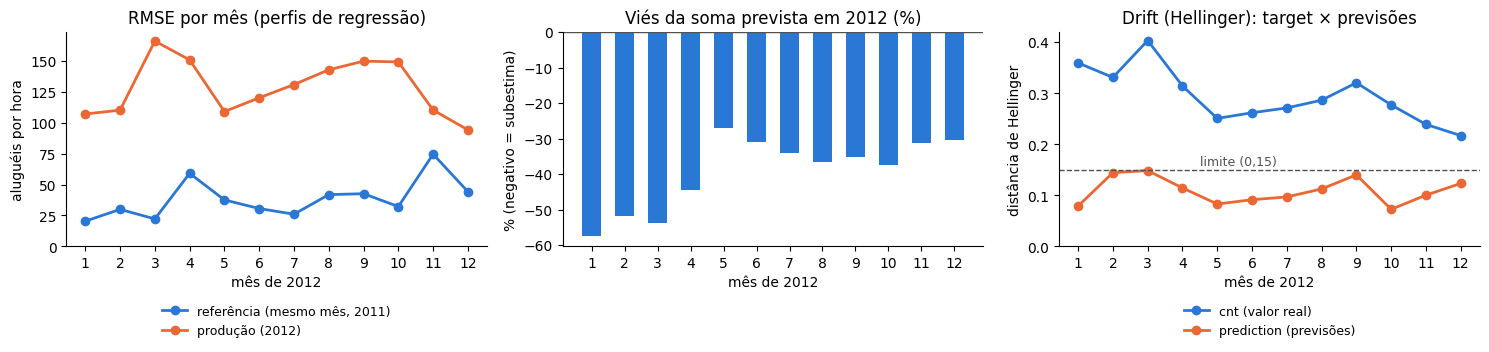

In [16]:
if WHYLOGS_AVAILABLE:
    meses = monthly.index
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

    ax[0].plot(meses, monthly["RMSE ref"], marker="o", ms=6, lw=2, color=BLUE, label="referência (mesmo mês, 2011)")
    ax[0].plot(meses, monthly["RMSE 2012"], marker="o", ms=6, lw=2, color=ORANGE, label="produção (2012)")
    ax[0].set_title("RMSE por mês (perfis de regressão)"); ax[0].set_ylabel("aluguéis por hora"); ax[0].set_ylim(bottom=0)

    ax[1].bar(meses, monthly["viés 2012"] * 100, color=BLUE, width=0.6)
    ax[1].axhline(0, color=GRAY, lw=1)
    ax[1].set_title("Viés da soma prevista em 2012 (%)"); ax[1].set_ylabel("% (negativo = subestima)")

    ax[2].plot(meses, monthly["Hellinger cnt"], marker="o", ms=6, lw=2, color=BLUE, label="cnt (valor real)")
    ax[2].plot(meses, monthly["Hellinger prediction"], marker="o", ms=6, lw=2, color=ORANGE, label="prediction (previsões)")
    ax[2].axhline(0.15, color=GRAY, lw=1, ls="--"); ax[2].text(4.5, 0.158, "limite (0,15)", color=GRAY, fontsize=9)
    ax[2].set_title("Drift (Hellinger): target × previsões"); ax[2].set_ylabel("distância de Hellinger"); ax[2].set_ylim(bottom=0)

    for a in ax:
        a.set_xticks(range(1, 13)); a.set_xlabel("mês de 2012"); a.spines[["top", "right"]].set_visible(False)
    for a in (ax[0], ax[2]):
        a.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
    plt.tight_layout(); fig.savefig(RUNS_DIR / "whylogs_monthly_2012.png", dpi=130, bbox_inches="tight"); plt.show()

**Leitura mês a mês:**

- **Desempenho e viés reprovam nos 12 meses.** O viés vai de −57% (janeiro) a −27% (maio), os mesmos números do projeto do Deepchecks, agora calculados a partir de perfis diários somados.
- **Drift do target reprova nos 12 meses.** A distância de Hellinger de `cnt` fica entre 0,22 e 0,40.
- **Drift das previsões passa nos 12 meses**, embora fique perto do limite em fevereiro e março (0,14–0,15).
- **Drift das features reprova em 10 meses**, bem mais que no Deepchecks (2 de 12). Com cerca de 720 horas por mês, o histograma usado pela Hellinger fica mais "ruidoso" e a distância sobe. Parte disso é clima real (inverno e março de 2012 mais quentes, novembro mais frio), mas o limite de 0,15 precisaria ser recalibrado para lotes mensais.

Os perfis mensais de 2012 ficaram salvos em `runs/profiles/`, cerca de 70 KB cada. Com eles, qualquer comparação futura (outro mês, outro limite, outro algoritmo) pode ser refeita **sem os dados originais**.

## Conclusões

1. **O whylogs é um "registrador" de dados, não um avaliador de modelos.** Ele brilha em guardar histórico barato e auditável (perfis pequenos, com data, somáveis e sem dados brutos) e em regras de qualidade de dados. Para avaliar o modelo ele entrega métricas, mas não relatórios prontos.
2. **O teste de drift padrão gera alarmes demais.** Com p-valor, 7 de 13 colunas apareceram com drift por causa do tamanho da amostra. A distância de Hellinger deu um resultado coerente com o Deepchecks: só o target mudou.
3. **A lição central se repete nas três ferramentas:** as previsões não mudaram e só a comparação com o valor real revela o problema. No whylogs, isso exigiu montar a regra à mão (colunas `erro` e `erro_abs`).
4. **Monitorar por lote pequeno revela o que o anual esconde:** o perfil diário pegou o furacão Sandy, que passou despercebido no Deepchecks e na regra anual.
5. **Perfis somados são exatos** para contagens, médias e RMSE, o que permite guardar o diário e consolidar em mês ou ano depois.

### Limitações encontradas
- **Manutenção:** a última versão (1.6.4) é de dezembro de 2024 e não funciona com NumPy 2. Foi preciso fixar Python 3.11, NumPy < 2, SciPy < 1.14 e pandas < 2.3.
- **Relatórios online:** os HTML carregam jQuery, D3, Bootstrap e Handlebars da internet e **não abrem offline**.
- **Hellinger só para números:** colunas de texto ficam presas ao qui-quadrado.
- **Sem segmentos fracos nem gráfico de resíduos:** é preciso construir essa análise por fora.